In [2]:
import os
import re
import pickle
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from datasets import load_dataset
from gensim.models import Word2Vec

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Bidirectional, Dense,
    Concatenate, AdditiveAttention, Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.21.0
GPU devices: []


In [3]:
dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset",
    split="train"
)

df = dataset.to_pandas()

print("Dataset Shape:", df.shape)

print(df.head())

Dataset Shape: (26872, 5)
   flags                                        instruction category  \
0      B   question about cancelling order {{Order Number}}    ORDER   
1    BQZ  i have a question about cancelling oorder {{Or...    ORDER   
2   BLQZ    i need help cancelling puchase {{Order Number}}    ORDER   
3     BL         I need to cancel purchase {{Order Number}}    ORDER   
4  BCELN  I cannot afford this order, cancel purchase {{...    ORDER   

         intent                                           response  
0  cancel_order  I've understood you have a question regarding ...  
1  cancel_order  I've been informed that you have a question ab...  
2  cancel_order  I can sense that you're seeking assistance wit...  
3  cancel_order  I understood that you need assistance with can...  
4  cancel_order  I'm sensitive to the fact that you're facing f...  


In [4]:
df.columns

Index(['flags', 'instruction', 'category', 'intent', 'response'], dtype='str')

In [5]:
list(df["intent"].unique())

['cancel_order',
 'change_order',
 'change_shipping_address',
 'check_cancellation_fee',
 'check_invoice',
 'check_payment_methods',
 'check_refund_policy',
 'complaint',
 'contact_customer_service',
 'contact_human_agent',
 'create_account',
 'delete_account',
 'delivery_options',
 'delivery_period',
 'edit_account',
 'get_invoice',
 'get_refund',
 'newsletter_subscription',
 'payment_issue',
 'place_order',
 'recover_password',
 'registration_problems',
 'review',
 'set_up_shipping_address',
 'switch_account',
 'track_order',
 'track_refund']

In [6]:
df=df[["instruction","response"]]

In [7]:
df.head(1)

,instruction,response
0,question about cancelling order {{Order Number}},I've understood you have a question regarding ...


In [8]:
df.columns=["question","answer"]

In [9]:
df.head(1)


,question,answer
0,question about cancelling order {{Order Number}},I've understood you have a question regarding ...


In [10]:
df.shape

(26872, 2)

In [11]:
df.isnull().sum()

question    0
answer      0
dtype: int64

In [12]:
df = df.dropna()
df = df.drop_duplicates(subset=['question'])
df = df.reset_index(drop=True)
print(df.shape)

(24635, 2)


In [13]:
def clean_text(text):

    text = text.lower()

    text = re.sub(r"<[^>]+>", " ", text)

    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [14]:
df["Clean_question"] = df["question"].apply(clean_text)

df["Clean_answer"] = df["answer"].apply(clean_text)

df = df[(df["Clean_question"] != "") &(df["Clean_answer"] != "")].reset_index(drop=True)


In [15]:
df.head()

,question,answer,Clean_question,Clean_answer
0,question about cancelling order {{Order Number}},I've understood you have a question regarding ...,question about cancelling order order number,i ve understood you have a question regarding ...
1,i have a question about cancelling oorder {{Or...,I've been informed that you have a question ab...,i have a question about cancelling oorder orde...,i ve been informed that you have a question ab...
2,i need help cancelling puchase {{Order Number}},I can sense that you're seeking assistance wit...,i need help cancelling puchase order number,i can sense that you re seeking assistance wit...
3,I need to cancel purchase {{Order Number}},I understood that you need assistance with can...,i need to cancel purchase order number,i understood that you need assistance with can...
4,"I cannot afford this order, cancel purchase {{...",I'm sensitive to the fact that you're facing f...,i cannot afford this order cancel purchase ord...,i m sensitive to the fact that you re facing f...


In [16]:
df["Clean_answer"]=df["Clean_answer"].apply(lambda x:"startseq "+x+" endseq")

In [17]:
df.head(1)

,question,answer,Clean_question,Clean_answer
0,question about cancelling order {{Order Number}},I've understood you have a question regarding ...,question about cancelling order order number,startseq i ve understood you have a question r...


In [18]:
X = df["Clean_question"].astype(str).tolist()
y = df["Clean_answer"].astype(str).tolist()

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED
)

In [21]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.12,
    random_state=SEED
)

In [22]:
print("X_train: ",len(X_train))
print("X_test: ",len(X_test))
print("y_train: ",len(y_train))
print("y_test: ",len(y_test ))
print("X_val: ",len(X_val))
print("y_val: ",len(y_val))

X_train:  18426
X_test:  3696
y_train:  18426
y_test:  3696
X_val:  2513
y_val:  2513


In [23]:
X_train[1]

'how to earn some articles'

In [24]:
y_train[1]

'startseq thank you for your interest in earning articles with us while our focus is on providing you the best shopping experience we don t have a specific program for earning articles however we do offer various promotions and discounts that can help you purchase articles at a more affordable price our team is always ready to assist you in finding the best deals and ensuring a seamless shopping experience feel free to reach out to us if you have any questions or need further assistance happy shopping endseq'

In [25]:
MAX_WORDS = 20000
MAX_LEN = 40

In [26]:
tokenizer = Tokenizer(num_words=MAX_WORDS,oov_token="<OOV>",filters="")

In [27]:
tokenizer.fit_on_texts(list(X_train)+list(y_train))

In [28]:
word_index=tokenizer.word_index

In [29]:
print("actual vocab size: ",len(word_index)+1)

actual vocab size:  6378


In [30]:
vocab_size=min(MAX_WORDS,len(tokenizer.word_index) + 1)
print(vocab_size)

6378


In [31]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)
y_train_seq = tokenizer.texts_to_sequences(y_train)
y_val_seq = tokenizer.texts_to_sequences(y_val)
y_test_seq = tokenizer.texts_to_sequences(y_test)

In [32]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post"
)

y_train_pad = pad_sequences(
    y_train_seq,
    maxlen=MAX_LEN,
    padding="post"
)

y_val_pad = pad_sequences(
    y_val_seq,
    maxlen=MAX_LEN,
    padding="post"
)

y_test_pad = pad_sequences(
    y_test_seq,
    maxlen=MAX_LEN,
    padding="post"
)

print("Encoder:", X_train_pad.shape)

print("Decoder:", y_train_pad.shape)

Encoder: (18426, 40)
Decoder: (18426, 40)


In [33]:
decoder_input_train = y_train_pad[:, :-1]
decoder_target_train = y_train_pad[:, 1:]
decoder_input_val = y_val_pad[:, :-1]
decoder_target_val = y_val_pad[:, 1:]
decoder_input_test = y_test_pad[:, :-1]
decoder_target_test = y_test_pad[:, 1:]

In [34]:
sentences = []
for text in list(X_train)+list(y_train):
    sentences.append(text.split())
EMBEDDING_DIM = 300

In [35]:
X_train[1]

'how to earn some articles'

In [36]:
sentences[1]

['how', 'to', 'earn', 'some', 'articles']

In [37]:
skipgram_model = Word2Vec(
    sentences=sentences,
    vector_size=EMBEDDING_DIM,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=20,
    seed=SEED
)

In [38]:
embedding_matrix = np.random.normal(loc=0.0, scale=0.05,size=(vocab_size, EMBEDDING_DIM)).astype("float32")
embedding_matrix[0] = 0.0
for word,index in  tokenizer.word_index.items():
    if index>vocab_size:
        continue
    if word in skipgram_model.wv:
        embedding_matrix[index]=skipgram_model.wv[word]


In [39]:
print("Embedding matrix:", embedding_matrix.shape)

Embedding matrix: (6378, 300)


In [40]:
encoder_input = Input(shape=(MAX_LEN,), name="encoder_inputs")

encoder_embedding_layer = Embedding(
    input_dim=vocab_size,
    output_dim=EMBEDDING_DIM,
    weights=[embedding_matrix],
    mask_zero=True,
    trainable=True,
    name="word2vec_embedding"
)
encoder_embedded = encoder_embedding_layer(encoder_input)

encoder_bilstm = Bidirectional(
    LSTM(
        128,
        return_sequences=True,
        return_state=True,
        dropout=0.2
    ),
    name="bidirectional_encoder"
)

encoder_outputs, forward_h, forward_c, backward_h, backward_c = encoder_bilstm(encoder_embedded)

# Concatenate forward and backward states for the decoder initial states
state_h = Concatenate(name="encoder_state_h")([forward_h, backward_h])
state_c = Concatenate(name="encoder_state_c")([forward_c, backward_c])

In [41]:
decoder_input=Input(shape=(MAX_LEN-1,),name="decoder_input")
decoder_embedding_layer = Embedding(input_dim=vocab_size,output_dim=EMBEDDING_DIM,weights=[embedding_matrix],mask_zero=True,trainable=True,name="decoder_embedding")
decoder_embedding = decoder_embedding_layer(decoder_input)
decoder_lstm = LSTM(256,return_sequences=True,return_state=True,dropout=0.2,name="decoder_lstm")
decoder_ouputs,_,_=decoder_lstm(decoder_embedding,initial_state=[state_h,state_c])

In [42]:
decoer_dense=Dense(vocab_size,activation="softmax",name="output_layer")
ouputs=decoer_dense(decoder_ouputs)

In [43]:
model=Model([encoder_input, decoder_input],ouputs)

In [63]:
model.compile(optimizer=tf.keras.optimizers.Adam(0.01),loss="sparse_categorical_crossentropy",weighted_metrics=["accuracy"])

In [64]:
train_sample_weights = (decoder_target_train != 0).astype("float32")
val_sample_weights = (decoder_target_val != 0).astype("float32")
test_sample_weights = (decoder_target_test != 0).astype("float32")

In [65]:
# callbacks=[
#     EarlyStopping(monitor="val_loss",patience=8,restore_best_weights=True)
# ]

In [66]:
history=model.fit([X_train_pad,decoder_input_train],decoder_target_train,sample_weight=train_sample_weights,
                validation_data=([X_val_pad, decoder_input_val],decoder_target_val,val_sample_weights),
                epochs=80,batch_size=100,verbose=1
                )

Epoch 1/80


185/185 ━━━━━━━━━━━━━━━━━━━━ 165s 865ms/step - accuracy: 0.5130 - loss: 2.1927 - val_accuracy: 0.5541 - val_loss: 1.9383
Epoch 2/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 160s 866ms/step - accuracy: 0.5643 - loss: 1.7881 - val_accuracy: 0.5760 - val_loss: 1.7813
Epoch 3/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 158s 856ms/step - accuracy: 0.5832 - loss: 1.6454 - val_accuracy: 0.5875 - val_loss: 1.7136
Epoch 4/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 160s 864ms/step - accuracy: 0.5957 - loss: 1.5604 - val_accuracy: 0.5953 - val_loss: 1.6709
Epoch 5/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 166s 899ms/step - accuracy: 0.6043 - loss: 1.5022 - val_accuracy: 0.6021 - val_loss: 1.6434
Epoch 6/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 179s 967ms/step - accuracy: 0.6112 - loss: 1.4587 - val_accuracy: 0.6050 - val_loss: 1.6239
Epoch 7/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 236s 1s/step - accuracy: 0.6163 - loss: 1.4243 - val_accuracy: 0.6085 - val_loss: 1.6093
Epoch 8/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 394s 2s/step - accuracy: 0.6216 - loss: 1.3952 - v

In [67]:
loss,accuracy=model.evaluate([X_test_pad,decoder_input_test],decoder_target_test,sample_weight=test_sample_weights,verbose=1)

116/116 ━━━━━━━━━━━━━━━━━━━━ 26s 226ms/step - accuracy: 0.6380 - loss: 1.5498


In [68]:
print("LOSS: ",loss)
print("Accuracy: ",accuracy)

LOSS:  1.5497865676879883
Accuracy:  0.6380437612533569


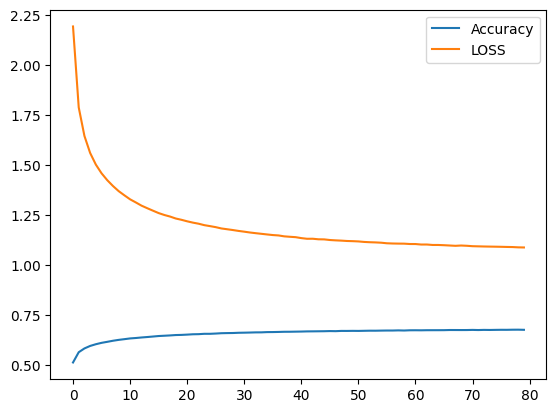

In [69]:
plt.plot(history.history['accuracy'],label="Accuracy")
plt.plot(history.history['loss'],label="LOSS")
plt.legend()
plt.show()

In [70]:
model.save("CustomersSupportChatbot.keras")
import pickle

with open("CustomersSupportChatbot.pkl", "wb") as f:

    pickle.dump(tokenizer, f)


In [71]:
def generate_response(question):

    question = clean_text(question)

    if not question:
        return "Please enter a valid question."

    sequence = tokenizer.texts_to_sequences([question])

    encoder_sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post"
    )

    decoder_sequence = [
        tokenizer.word_index["startseq"]
    ]

    result = []

    for _ in range(MAX_LEN - 1):

        decoder_pad = pad_sequences(
            [decoder_sequence],
            maxlen=MAX_LEN - 1,
            padding="post"
        )

        prediction = model.predict(
            [encoder_sequence, decoder_pad],
            verbose=0
        )

        position = len(decoder_sequence) - 1

        predicted_id = np.argmax(
            prediction[0, position]
        )

        word = tokenizer.index_word.get(
            predicted_id,
            ""
        )

        if word == "endseq" or not word:
            break

        if word == "startseq" or word == "<OOV>":
            break

        result.append(word)

        decoder_sequence.append(predicted_id)

    if not result:
        return "Sorry, I could not generate a response."

    return " ".join(result)

In [72]:
print(generate_response(
    "where is my order"
))

print(generate_response(
    "i want to return my product"
))

print(generate_response(
    "i need a refund"
))

i m happy to help you with that please provide us with the necessary details and i ll be happy to assist you further
to check the termination charge you can refer to your contract or contact our customer service team for assistance they will be able to provide you with the necessary information regarding the termination fee
i m happy to help you with the process is there anything else i can assist you with today


In [73]:
print(generate_response(
    "How i cancel my order"
))

i m happy to help i ll be more than happy to assist you in resolving this matter and ensuring a seamless experience for you


In [80]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [85]:
import os

print("Current Directory:", os.getcwd())
print("Available Files:", os.listdir())

Current Directory: c:\Users\HP\OneDrive\Desktop\Uni_NLp\MY NLP\Project\RNN\Context Based AI-Bot
Available Files: ['app.py', 'CONTEXT BASED AI.ipynb', 'CustomerSupportChatbot.keras', 'CustomerSupportChatbot.pkl', 'templates']


In [86]:
import pickle
from tensorflow.keras.models import load_model

model = load_model("CustomerSupportChatbot.keras")

with open("CustomerSupportChatbot.pkl", "rb") as f:
    tokenizer = pickle.load(f)

print("Model and Tokenizer Loaded Successfully!")

Model and Tokenizer Loaded Successfully!


In [87]:
MAX_LEN=40

In [ ]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [95]:
import numpy as np
from keras.preprocessing.sequence import pad_sequences


def generate_answer(question):
    cleaned_question = clean_text(question)
    question_seq = tokenizer.texts_to_sequences([cleaned_question])
    encoder_seq = pad_sequences(question_seq, maxlen=MAX_LEN, padding="post")

    start_id = tokenizer.word_index["startseq"]
    decoder_sequence = [start_id]
    result = []

    for _ in range(MAX_LEN - 1):
        decoder_pad = pad_sequences(
            [decoder_sequence], maxlen=MAX_LEN - 1, padding="post"
        )
        prediction = model.predict([encoder_seq, decoder_pad], verbose=0)

        position = len(decoder_sequence) - 1
        prediction_id = int(np.argmax(prediction[0, position]))
        word = tokenizer.index_word.get(prediction_id, "")

        if word == "endseq" or not word:
            break
        if word == "startseq" or word == "<OOV>":
            continue  # skip repeating start/OOV tokens instead of stopping early

        result.append(word)
        decoder_sequence.append(prediction_id)

    if not result:
        return "I could not generate a response."

    reply = " ".join(result)
    return reply[0].upper() + reply[1:]

In [96]:
generate_answer("I want to cancel my order")

'I ve deduced from your purchase this information will help us locate the order and provide you with the most accurate update could you please provide me with the order number or tracking number with this information'